In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto definido por el siguiente cuadro de prelaciones inmediatas.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT del proyecto utilizando el mínimo número de actividades ficticias y numere sus nodos de modo que todo arco vaya de un número menor a uno mayor.  "
pregunta_2 = "2. Para cada actividad ficticia, explique qué prelación transmite y por qué no puede evitarse.  "
pregunta_3 = "3. Las actividades C y D tienen las mismas predecesoras. ¿Pueden compartir nodo inicial y nodo final? Razone la respuesta.  "
pregunta_4 = "4. Enumere todas las rutas desde el nodo inicial al final e indique cuántas hay.  "
pregunta_5 = "5. Construya el cuadro de ancestros y compruebe que el grafo lo respeta.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT del proyecto utilizando el mínimo número de actividades ficticias y numere sus nodos de modo que todo arco vaya de un número menor a uno mayor.  

2. Para cada actividad ficticia, explique qué prelación transmite y por qué no puede evitarse.  

3. Las actividades C y D tienen las mismas predecesoras. ¿Pueden compartir nodo inicial y nodo final? Razone la respuesta.  

4. Enumere todas las rutas desde el nodo inicial al final e indique cuántas hay.  

5. Construya el cuadro de ancestros y compruebe que el grafo lo respeta.  

In [5]:
#| tbl-cap: "Cuadro de prelaciones del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , 'A,B'      ),
    ('D'     , 'A,B'      ),
    ('E'     , 'C'        ),
    ('F'     , 'D,E'      ),
    ('G'     , 'D'        ),
    ('H'     , 'F,G'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,"A,B"
D,"A,B"
E,C
F,"D,E"
G,D
H,"F,G"


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT del proyecto utilizando el mínimo número de actividades ficticias y numere sus nodos de modo que todo arco vaya de un número menor a uno mayor.  

Partimos del cuadro de prelaciones expandido: las filas dan las predecesoras inmediatas y las columnas las sucesoras. Dos actividades pueden compartir nodo final si tienen exactamente las mismas sucesoras, y nodo inicial si tienen las mismas predecesoras; en los demás casos hacen falta ficticias.

In [9]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H
activities,,,,,,,,
A,,,,,,,,
B,,,,,,,,
C,True,True,,,,,,
D,True,True,,,,,,
E,,,True,,,,,
F,,,,True,True,,,
G,,,,True,,,,
H,,,,,,True,True,


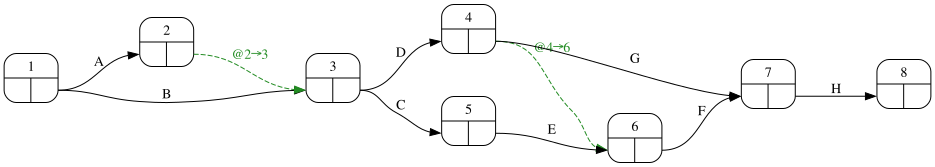

In [10]:
#| fig-cap: "Grafo PERT con numeración de nodos; las ficticias se dibujan discontinuas"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [11]:
print(f'El grafo tiene {len(proyecto.nodes)} nodos, {len(proyecto)} actividades reales '
      f'y {len(proyecto.dummies)} ficticias: {", ".join(proyecto.dummies)}')

El grafo tiene 8 nodos, 8 actividades reales y 2 ficticias: @2→3, @4→6


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Para cada actividad ficticia, explique qué prelación transmite y por qué no puede evitarse.  

Cada ficticia une el nodo final de unas actividades con el nodo inicial de otras. La prelación que transmite es «todas las que entran en su nodo origen preceden a todas las que salen de su nodo destino».

In [13]:
grafo = proyecto.pert_graph
def actividades_que_entran(nodo):
    return sorted(d['activity'] for _, _, d in grafo.in_edges(nodo, data=True) if not d['activity'].startswith('@'))
def actividades_que_salen(nodo):
    return sorted(d['activity'] for _, _, d in grafo.out_edges(nodo, data=True) if not d['activity'].startswith('@'))

filas = []
for origen, destino, d in grafo.edges(data=True):
    if d['activity'].startswith('@'):
        filas.append({'ficticia': d['activity'],
                      'entran en el nodo origen': ', '.join(actividades_que_entran(origen)),
                      'salen del nodo destino': ', '.join(actividades_que_salen(destino))})
pd.DataFrame(filas).set_index('ficticia')

,entran en el nodo origen,salen del nodo destino
ficticia,,
@2→3,A,"C, D"
@4→6,D,F


Si en lugar de la ficticia se fusionaran ambos nodos, las actividades que salen del nodo destino pasarían a tener como predecesoras a todas las que entran en el origen *y* a las que entran en el destino, que no es lo que dice el cuadro; y si se eliminara sin fusionar, se perdería la prelación. Por eso ninguna puede evitarse.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Las actividades C y D tienen las mismas predecesoras. ¿Pueden compartir nodo inicial y nodo final? Razone la respuesta.  

C y D tienen las mismas predecesoras, así que pueden compartir el nodo inicial. Pero dos arcos no pueden unir el mismo par de nodos (el grafo no distinguiría una actividad de la otra), de modo que sólo compartirán también el nodo final si además tienen las mismas sucesoras, y aun en ese caso una de las dos necesita una ficticia.

In [15]:
sucesoras = {act: sorted(s for s, ps in prelaciones.immediate_predecessor.items() if act in ps)
             for act in datos_proyecto.index}
print('Sucesoras de C:', sucesoras['C'])
print('Sucesoras de D:', sucesoras['D'])

Sucesoras de C: ['E']
Sucesoras de D: ['F', 'G']


## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Enumere todas las rutas desde el nodo inicial al final e indique cuántas hay.  

In [17]:
#| tbl-cap: "Rutas del grafo (sin ficticias)"
#| label: tbl-rutas
rutas = proyecto.paths(dummies=False)
pd.Series({ruta: ' - '.join(acts) for ruta, acts in rutas.items()}).to_frame('actividades')

,actividades
Route_1,A - C - E - F - H
Route_2,A - D - F - H
Route_3,A - D - G - H
Route_4,B - C - E - F - H
Route_5,B - D - F - H
Route_6,B - D - G - H


In [18]:
print(f'El grafo tiene {len(rutas)} rutas entre el nodo inicial y el final.')

El grafo tiene 6 rutas entre el nodo inicial y el final.


## Apartado 5

In [19]:
display(Markdown(pregunta_5))

5. Construya el cuadro de ancestros y compruebe que el grafo lo respeta.  

In [20]:
#| tbl-cap: "Cuadro de ancestros"
#| label: tbl-ancestros
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,"A, B"
D,"A, B"
E,"A, B, C"
F,"A, B, C, D, E"
G,"A, B, D"
H,"A, B, C, D, E, F, G"


Para cada actividad, el conjunto de actividades que aparecen antes que ella en alguna ruta debe coincidir con su fila del cuadro de ancestros:

In [21]:
ancestros = proyecto.distant_predecessor()
comprobacion = {}
for act in datos_proyecto.index:
    por_rutas = set()
    for acts in rutas.values():
        if act in acts:
            por_rutas |= set(acts[:acts.index(act)])
    comprobacion[act] = por_rutas == set(ancestros[act])
pd.Series(comprobacion).to_frame('coincide')

,coincide
A,True
B,True
C,True
D,True
E,True
F,True
G,True
H,True
